# VortexMD vs. MDAnalysis — RMSD & XTC Decompression Validation

This notebook validates **VortexMD**'s out-of-core XTC decompressor (`engine/headless-xtc.js`), binary header indexer (`engine/indexer.js`), and closed-form Horn unit-quaternion superposition (`engine/analytics.js`) against **MDAnalysis** (`MDAnalysis.analysis.rms.RMSD`, Theobald QCP solver) on the benchmark trajectory (`16pk_A.pdb` + `16pk_A.xtc`, 6,378 atoms, 1,001 frames, 100 ns) and the CI/CD demo trajectory (`demo.xtc`, 100 frames).

**How to run:**
1. Open in Google Colab and click **Runtime → Run all**.
2. Approve Google Drive mounting when prompted.
3. All logs, frame-by-frame CSVs, summary JSON/CSV tables, and 300 DPI publication figures will be written automatically to `MyDrive/vortexMD_rmsd_check/results/`.


In [1]:
# 1. Mount Google Drive and configure paths + persistent logging
import os
import sys
import json
import time
import logging
import subprocess
from pathlib import Path
from datetime import datetime, timezone

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

WORK_DIR = Path('/content/drive/MyDrive/vortexMD_rmsd_check')
if not WORK_DIR.exists():
    raise FileNotFoundError(
        f"Folder not found: {WORK_DIR}. Make sure 'vortexMD_rmsd_check' is in your Google Drive root (MyDrive)."
    )

RESULTS_DIR = WORK_DIR / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
LOG_PATH = RESULTS_DIR / 'validation_run.log'

# Configure dual logger (notebook stdout + validation_run.log)
logger = logging.getLogger('vortexmd_validation')
logger.setLevel(logging.INFO)
logger.handlers.clear()
fmt = logging.Formatter('%(asctime)s | %(levelname)s | %(message)s', datefmt='%Y-%m-%d %H:%M:%S')
fh = logging.FileHandler(LOG_PATH, mode='w', encoding='utf-8')
fh.setFormatter(fmt)
sh = logging.StreamHandler(sys.stdout)
sh.setFormatter(fmt)
logger.addHandler(fh)
logger.addHandler(sh)

PDB_PATH = WORK_DIR / '16pk_A.pdb'
XTC_PATH = WORK_DIR / '16pk_A.xtc'
DEMO_XTC_PATH = WORK_DIR / 'demo.xtc'
ENGINE_DIR = WORK_DIR / 'engine'

required_files = [
    PDB_PATH, XTC_PATH, DEMO_XTC_PATH,
    ENGINE_DIR / 'indexer.js',
    ENGINE_DIR / 'headless-xtc.js',
    ENGINE_DIR / 'analytics.js',
    ENGINE_DIR / 'trajectory-validator.js',
]
missing = [str(p) for p in required_files if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing required files in {WORK_DIR}:\n" + "\n".join(missing))

logger.info("=== VortexMD vs. MDAnalysis Validation Started ===")
logger.info(f"Working folder: {WORK_DIR}")
logger.info(f"Results folder: {RESULTS_DIR}")
for p in required_files:
    logger.info(f"Verified input: {p.relative_to(WORK_DIR)} ({p.stat().st_size:,} bytes)")


Mounted at /content/drive
2026-11-24 04:49:38 | INFO | === VortexMD vs. MDAnalysis Validation Started ===


INFO:vortexmd_validation:=== VortexMD vs. MDAnalysis Validation Started ===


2026-11-24 04:49:38 | INFO | Working folder: /content/drive/MyDrive/vortexMD_rmsd_check


INFO:vortexmd_validation:Working folder: /content/drive/MyDrive/vortexMD_rmsd_check


2026-11-24 04:49:38 | INFO | Results folder: /content/drive/MyDrive/vortexMD_rmsd_check/results


INFO:vortexmd_validation:Results folder: /content/drive/MyDrive/vortexMD_rmsd_check/results


... (10 outputs left out)

2026-11-24 04:49:38 | INFO | Verified input: engine/analytics.js (12,805 bytes)


INFO:vortexmd_validation:Verified input: engine/analytics.js (12,805 bytes)


2026-11-24 04:49:38 | INFO | Verified input: engine/trajectory-validator.js (6,802 bytes)


INFO:vortexmd_validation:Verified input: engine/trajectory-validator.js (6,802 bytes)


In [2]:
# 2. Install MDAnalysis and verify Python & Node.js runtime versions
try:
    import MDAnalysis as mda
except ImportError:
    logger.info("Installing MDAnalysis...")
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'MDAnalysis'])
    import MDAnalysis as mda

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from MDAnalysis.analysis import rms

# Verify Node.js (Colab ships with Node.js pre-installed)
node_ver = subprocess.check_output(['node', '-v'], text=True).strip()
logger.info(f"Python:     {sys.version.split()[0]}")
logger.info(f"MDAnalysis: {mda.__version__}")
logger.info(f"NumPy:      {np.__version__}")
logger.info(f"Pandas:     {pd.__version__}")
logger.info(f"Node.js:    {node_ver}")


2026-11-24 04:49:38 | INFO | Installing MDAnalysis...


INFO:vortexmd_validation:Installing MDAnalysis...


2026-11-24 04:49:44 | INFO | Python:     3.13.18


INFO:vortexmd_validation:Python:     3.13.18


2026-11-24 04:49:44 | INFO | MDAnalysis: 2.11.0


INFO:vortexmd_validation:MDAnalysis: 2.11.0


... (2 outputs left out)

2026-11-24 04:49:44 | INFO | Pandas:     2.2.3


INFO:vortexmd_validation:Pandas:     2.2.3


2026-11-24 04:49:44 | INFO | Node.js:    v22.23.4


INFO:vortexmd_validation:Node.js:    v22.23.4


In [3]:
# 3. Run MDAnalysis reference RMSD (Theobald QCP) on 16pk_A.xtc (1,001 frames) and demo.xtc (100 frames)
logger.info("Loading 16pk_A.pdb + 16pk_A.xtc in MDAnalysis...")
t0 = time.perf_counter()
u = mda.Universe(str(PDB_PATH), str(XTC_PATH))
n_atoms = len(u.atoms)
n_frames = len(u.trajectory)
n_ca = len(u.select_atoms('protein and name CA'))
n_bb = len(u.select_atoms('protein and name N CA C O'))
logger.info(f"MDAnalysis Universe loaded: {n_atoms} atoms, {n_ca} CA, {n_bb} backbone (N,CA,C,O), {n_frames} frames")

# 3a. C-alpha fit & calc vs XTC frame 0 (matches VortexMD default)
r_ca = rms.RMSD(u, u, select='protein and name CA', ref_frame=0).run()
times_ps = r_ca.results.rmsd[:, 1]
mda_ca = r_ca.results.rmsd[:, 2]

# 3b. Backbone (N, CA, C, O) fit & calc vs XTC frame 0
r_bb = rms.RMSD(u, u, select='protein and name N CA C O', ref_frame=0).run()
mda_bb = r_bb.results.rmsd[:, 2]

# 3c. All atoms fit & calc vs XTC frame 0
r_all = rms.RMSD(u, u, select='all', ref_frame=0).run()
mda_all = r_all.results.rmsd[:, 2]

# 3d. Separate fit (CA) & calc (all atoms) vs XTC frame 0
r_fitca_all = rms.RMSD(u, u, select='protein and name CA', groupselections=['all'], ref_frame=0).run()
mda_fitca_all = r_fitca_all.results.rmsd[:, 3]

# 3e. C-alpha vs external PDB reference structure (measures PDB vs XTC-f0 reference gap)
ref_pdb = mda.Universe(str(PDB_PATH))
r_ca_pdb = rms.RMSD(u, ref_pdb, select='protein and name CA').run()
mda_ca_pdb = r_ca_pdb.results.rmsd[:, 2]

# 3f. Capture MDAnalysis xdrfile C-reader coordinates on sampled frames for coordinate parity check
sample_frame_ids = [0, 100, 500, n_frames - 1]
mda_sample_coords = {}
for fid in sample_frame_ids:
    u.trajectory[fid]
    mda_sample_coords[fid] = u.atoms.positions.copy().astype(np.float64)

mda_elapsed = time.perf_counter() - t0
logger.info(f"MDAnalysis full 1,001-frame suite completed in {mda_elapsed:.2f} s")

# 3g. Also run MDAnalysis on 100-frame demo.xtc
u_demo = mda.Universe(str(PDB_PATH), str(DEMO_XTC_PATH))
r_demo_ca = rms.RMSD(u_demo, u_demo, select='protein and name CA', ref_frame=0).run()
mda_demo_ca = r_demo_ca.results.rmsd[:, 2]
logger.info(f"MDAnalysis demo.xtc loaded: {len(u_demo.trajectory)} frames (C-alpha RMSD range: {mda_demo_ca.min():.3f}-{mda_demo_ca.max():.3f} A)")


2026-11-24 04:49:44 | INFO | Loading 16pk_A.pdb + 16pk_A.xtc in MDAnalysis...


INFO:vortexmd_validation:Loading 16pk_A.pdb + 16pk_A.xtc in MDAnalysis...


2026-11-24 04:49:50 | INFO | MDAnalysis Universe loaded: 6378 atoms, 415 CA, 1659 backbone (N,CA,C,O), 1001 frames


INFO:vortexmd_validation:MDAnalysis Universe loaded: 6378 atoms, 415 CA, 1659 backbone (N,CA,C,O), 1001 frames


2026-11-24 04:49:55 | INFO | MDAnalysis full 1,001-frame suite completed in 11.34 s


INFO:vortexmd_validation:MDAnalysis full 1,001-frame suite completed in 11.34 s


2026-11-24 04:50:00 | INFO | MDAnalysis demo.xtc loaded: 100 frames (C-alpha RMSD range: 0.000-3.723 A)


INFO:vortexmd_validation:MDAnalysis demo.xtc loaded: 100 frames (C-alpha RMSD range: 0.000-3.723 A)


In [4]:
# 4. Run VortexMD's actual JS engine (indexer.js + headless-xtc.js + analytics.js) via Node.js
node_script = f'''
import fs from 'node:fs';
import {{ performance }} from 'node:perf_hooks';

import {{ scanTrajectoryBinary }} from '{(ENGINE_DIR / "indexer.js").as_posix()}';
import {{ decodeHeadlessXtcFrames }} from '{(ENGINE_DIR / "headless-xtc.js").as_posix()}';
import {{ hornSuperpose }} from '{(ENGINE_DIR / "analytics.js").as_posix()}';
import {{ validateTrajectoryCompatibility }} from '{(ENGINE_DIR / "trajectory-validator.js").as_posix()}';

const pdbPath = '{PDB_PATH.as_posix()}';
const xtcPath = '{XTC_PATH.as_posix()}';
const demoXtcPath = '{DEMO_XTC_PATH.as_posix()}';

// Parse PDB atom indices
const pdbLines = fs.readFileSync(pdbPath, 'utf8').split('\\n');

const caIdx = [];
const bbIdx = [];
const pdbCoords = [];
let atomIdx = 0;

for (const l of pdbLines) {{
    if (l.startsWith('ATOM  ') || l.startsWith('HETATM')) {{
        const name = l.slice(12, 16).trim();

        pdbCoords.push(
            parseFloat(l.slice(30, 38)),
            parseFloat(l.slice(38, 46)),
            parseFloat(l.slice(46, 54))
        );

        if (name === 'CA') caIdx.push(atomIdx);

        if (
            name === 'N' ||
            name === 'CA' ||
            name === 'C' ||
            name === 'O'
        ) bbIdx.push(atomIdx);

        atomIdx++;
    }}
}}

const allIdx = Array.from({{ length: atomIdx }}, (_, i) => i);

async function runTrajectory(pathStr, computeAllModes = true) {{
  const t0 = performance.now();
  const buf = fs.readFileSync(pathStr);
  const ab = buf.buffer.slice(buf.byteOffset, buf.byteOffset + buf.byteLength);
  const blob = new Blob([ab]);
  Object.defineProperty(blob, 'name', {{ value: pathStr.split('/').pop() }});

  const validation = await validateTrajectoryCompatibility(blob, atomIdx, 'xtc');
  const offsets = await scanTrajectoryBinary(blob, atomIdx, blob.size, null, 'xtc');
  const tIndex = performance.now() - t0;

  const nFrames = offsets.length - 1;
  const frames = [];
  const tDec0 = performance.now();
  for (let f = 0; f < nFrames; f++) {{
    frames.push(decodeHeadlessXtcFrames(ab.slice(offsets[f], offsets[f + 1]), atomIdx)[0]);
  }}
  const tDecode = performance.now() - tDec0;

  const ref0 = frames[0];
  const tRmsd0 = performance.now();
  const caFast = frames.map(fr => hornSuperpose(fr, ref0, caIdx, caIdx, false).rmsd);
  const caAligned = computeAllModes ? frames.map(fr => hornSuperpose(fr, ref0, caIdx, caIdx, true).rmsd) : [];
  const bbFast = computeAllModes ? frames.map(fr => hornSuperpose(fr, ref0, bbIdx, bbIdx, false).rmsd) : [];
  const allFast = computeAllModes ? frames.map(fr => hornSuperpose(fr, ref0, allIdx, allIdx, false).rmsd) : [];
  const fitCaAll = computeAllModes ? frames.map(fr => hornSuperpose(fr, ref0, caIdx, allIdx, false).rmsd) : [];
  const tRmsd = performance.now() - tRmsd0;

  const sampleCoords = {{}};
  if (computeAllModes) {{
    for (const fid of [0, 100, 500, nFrames - 1]) {{
      sampleCoords[fid] = Array.from(frames[fid]);
    }}
  }}

  return {{
    valid: validation.valid,
    nFrames,
    detectedDeltaTime: offsets.detectedDeltaTime,
    isTimeCalibrated: offsets.isTimeCalibrated,
    indexMs: Math.round(tIndex),
    decodeMs: Math.round(tDecode),
    rmsdMs: Math.round(tRmsd),
    caFast, caAligned, bbFast, allFast, fitCaAll,
    sampleCoords
  }};
}}

const fullRes = await runTrajectory(xtcPath, true);
const demoRes = await runTrajectory(demoXtcPath, false);
fs.writeFileSync('/tmp/vortexmd_colab_out.json', JSON.stringify({{ fullRes, demoRes }}));
console.log(JSON.stringify({{
  full_frames: fullRes.nFrames, full_dt: fullRes.detectedDeltaTime,
  full_index_ms: fullRes.indexMs, full_decode_ms: fullRes.decodeMs, full_rmsd_ms: fullRes.rmsdMs,
  demo_frames: demoRes.nFrames, demo_dt: demoRes.detectedDeltaTime
}}));
'''

logger.info("Running VortexMD JS engine (indexer + headless-xtc + hornSuperpose) via Node.js...")

result = subprocess.run(
    ['node', '--input-type=module', '-e', node_script],
    capture_output=True,
    text=True
)

print("========== NODE STDOUT ==========")
print(result.stdout)

print("========== NODE STDERR ==========")
print(result.stderr)

print("========== RETURN CODE ==========")
print(result.returncode)

if result.returncode != 0:
    raise RuntimeError("VortexMD Node.js engine execution failed")

node_summary = result.stdout.strip()

logger.info(f"Node.js VortexMD engine summary: {node_summary}")

with open('/tmp/vortexmd_colab_out.json') as f:
    vmd_data = json.load(f)

full_vmd = vmd_data['fullRes']
demo_vmd = vmd_data['demoRes']


2026-11-24 05:02:38 | INFO | Running VortexMD JS engine (indexer + headless-xtc + hornSuperpose) via Node.js...


INFO:vortexmd_validation:Running VortexMD JS engine (indexer + headless-xtc + hornSuperpose) via Node.js...


========== NODE STDOUT ==========
{"full_frames":1001,"full_dt":100,"full_index_ms":154,"full_decode_ms":2854,"full_rmsd_ms":1165,"demo_frames":100,"demo_dt":100}

========== NODE STDERR ==========

========== RETURN CODE ==========
0
2026-11-24 05:02:46 | INFO | Node.js VortexMD engine summary: {"full_frames":1001,"full_dt":100,"full_index_ms":154,"full_decode_ms":2854,"full_rmsd_ms":1165,"demo_frames":100,"demo_dt":100}


INFO:vortexmd_validation:Node.js VortexMD engine summary: {"full_frames":1001,"full_dt":100,"full_index_ms":154,"full_decode_ms":2854,"full_rmsd_ms":1165,"demo_frames":100,"demo_dt":100}


In [5]:
# 5. Quantify numerical gaps, verify coordinate parity, and export CSV/JSON results
def gap_stats(name, vmd_arr, mda_arr):
    v = np.asarray(vmd_arr, dtype=np.float64)
    m = np.asarray(mda_arr, dtype=np.float64)
    diff = np.abs(v - m)
    diff_3dp = np.abs(v - np.round(m, 3))
    corr = float(np.corrcoef(v, m)[0, 1]) if np.std(v) > 0 else 1.0
    return {
        'Mode': name,
        'Frames': int(len(v)),
        'VMD Min (A)': round(float(v.min()), 3),
        'VMD Max (A)': round(float(v.max()), 3),
        'VMD Mean (A)': round(float(v.mean()), 4),
        'Max |Delta| vs Unrounded MDA (A)': round(float(diff.max()), 6),
        'Mean |Delta| vs Unrounded MDA (A)': round(float(diff.mean()), 6),
        'RMSE vs Unrounded MDA (A)': round(float(np.sqrt(np.mean(diff ** 2))), 6),
        'Pearson r': round(corr, 9),
        'Max |Delta| after 3dp Round (A)': round(float(diff_3dp.max()), 6),
        'Frames Differing after 3dp Round': int(np.sum(diff_3dp > 1e-6)),
    }

rows = [
    gap_stats('16pk_A: C-alpha (fit=CA, calc=CA, ref=XTC f0)', full_vmd['caFast'], mda_ca),
    gap_stats('16pk_A: C-alpha aligned-path vs fast-path', full_vmd['caAligned'], full_vmd['caFast']),
    gap_stats('16pk_A: Backbone N,CA,C,O (ref=XTC f0)', full_vmd['bbFast'], mda_bb),
    gap_stats('16pk_A: All-atom 6,378 (ref=XTC f0)', full_vmd['allFast'], mda_all),
    gap_stats('16pk_A: Separate Fit=CA / Calc=All (ref=XTC f0)', full_vmd['fitCaAll'], mda_fitca_all),
    gap_stats('16pk_A: C-alpha (VMD XTC-f0 vs MDA PDB ref)', full_vmd['caFast'], mda_ca_pdb),
    gap_stats('demo.xtc (100f): C-alpha (ref=XTC f0)', demo_vmd['caFast'], mda_demo_ca),
]
summary_df = pd.DataFrame(rows)

# Coordinate-level XTC decompression parity check (VortexMD headless-xtc vs MDAnalysis xdrfile)
coord_checks = {}
max_coord_err = 0.0
for fid in sample_frame_ids:
    v_xyz = np.asarray(full_vmd['sampleCoords'][str(fid)], dtype=np.float64).reshape(-1, 3)
    m_xyz = mda_sample_coords[fid]
    err = float(np.max(np.abs(v_xyz - m_xyz)))
    max_coord_err = max(max_coord_err, err)
    coord_checks[f'frame_{fid}_max_abs_coord_diff_A'] = round(err, 8)

logger.info(f"XTC Decompression Coordinate Parity (VortexMD vs MDAnalysis xdrfile): {coord_checks}")

# Save frame-by-frame CSVs
frame_df = pd.DataFrame({
    'frame': np.arange(1, n_frames + 1),
    'time_ns': np.round(times_ps / 1000.0, 4),
    'mda_ca_A': np.round(mda_ca, 6),
    'vmd_ca_A': full_vmd['caFast'],
    'delta_ca_A': np.round(np.asarray(full_vmd['caFast']) - mda_ca, 6),
    'mda_bb_A': np.round(mda_bb, 6),
    'vmd_bb_A': full_vmd['bbFast'],
    'delta_bb_A': np.round(np.asarray(full_vmd['bbFast']) - mda_bb, 6),
    'mda_all_A': np.round(mda_all, 6),
    'vmd_all_A': full_vmd['allFast'],
    'delta_all_A': np.round(np.asarray(full_vmd['allFast']) - mda_all, 6),
    'mda_fitca_calcall_A': np.round(mda_fitca_all, 6),
    'vmd_fitca_calcall_A': full_vmd['fitCaAll'],
    'delta_fitca_calcall_A': np.round(np.asarray(full_vmd['fitCaAll']) - mda_fitca_all, 6),
    'mda_ca_pdb_ref_A': np.round(mda_ca_pdb, 6),
})
frame_df.to_csv(RESULTS_DIR / 'rmsd_frame_by_frame_16pk_A.csv', index=False)

demo_df = pd.DataFrame({
    'frame': np.arange(1, len(mda_demo_ca) + 1),
    'mda_ca_A': np.round(mda_demo_ca, 6),
    'vmd_ca_A': demo_vmd['caFast'],
    'delta_ca_A': np.round(np.asarray(demo_vmd['caFast']) - mda_demo_ca, 6),
})
demo_df.to_csv(RESULTS_DIR / 'rmsd_frame_by_frame_demo.csv', index=False)

summary_df.to_csv(RESULTS_DIR / 'rmsd_gap_summary.csv', index=False)
with open(RESULTS_DIR / 'rmsd_gap_summary.json', 'w') as jf:
    json.dump({
        'timestamp_utc': datetime.now(timezone.utc).isoformat(),
        'environment': {
            'python': sys.version.split()[0],
            'MDAnalysis': mda.__version__,
            'numpy': np.__version__,
            'node': node_ver,
        },
        'dataset': {'pdb': PDB_PATH.name, 'xtc': XTC_PATH.name, 'atoms': n_atoms, 'ca_atoms': n_ca, 'frames': n_frames},
        'coordinate_decompression_parity': coord_checks,
        'rmsd_comparison': rows,
    }, jf, indent=2)

# Hard scientific assertions
assert max_coord_err < 1e-4, f"XTC coordinate mismatch: {max_coord_err} A"
assert rows[0]['Max |Delta| vs Unrounded MDA (A)'] <= 0.00055, "C-alpha RMSD gap exceeded rounding bound!"
logger.info("ALL VALIDATION ASSERTIONS PASSED: VortexMD matches MDAnalysis within 3-decimal rounding (<= 0.0005 A).")
display(summary_df)


2026-11-24 05:03:02 | INFO | XTC Decompression Coordinate Parity (VortexMD vs MDAnalysis xdrfile): {'frame_0_max_abs_coord_diff_A': 7.63e-06, 'frame_100_max_abs_coord_diff_A': 7.63e-06, 'frame_500_max_abs_coord_diff_A': 7.63e-06, 'frame_1000_max_abs_coord_diff_A': 7.63e-06}


INFO:vortexmd_validation:XTC Decompression Coordinate Parity (VortexMD vs MDAnalysis xdrfile): {'frame_0_max_abs_coord_diff_A': 7.63e-06, 'frame_100_max_abs_coord_diff_A': 7.63e-06, 'frame_500_max_abs_coord_diff_A': 7.63e-06, 'frame_1000_max_abs_coord_diff_A': 7.63e-06}


2026-11-24 05:03:02 | INFO | ALL VALIDATION ASSERTIONS PASSED: VortexMD matches MDAnalysis within 3-decimal rounding (<= 0.0005 A).


INFO:vortexmd_validation:ALL VALIDATION ASSERTIONS PASSED: VortexMD matches MDAnalysis within 3-decimal rounding (<= 0.0005 A).


,Mode,Frames,VMD Min (A),VMD Max (A),VMD Mean (A),Max |Delta| vs Unrounded MDA (A),Mean |Delta| vs Unrounded MDA (A),RMSE vs Unrounded MDA (A),Pearson r,Max |Delta| after 3dp Round (A),Frames Differing after 3dp Round
0,"16pk_A: C-alpha (fit=CA, calc=CA, ref=XTC f0)",1001,0.0,3.874,2.6820,0.000500,0.000247,0.000286,1.0,0.0,0
1,16pk_A: C-alpha aligned-path vs fast-path,1001,0.0,3.874,2.6820,0.000000,0.000000,0.000000,1.0,0.0,0
2,"16pk_A: Backbone N,CA,C,O (ref=XTC f0)",1001,0.0,3.877,2.6904,0.000499,0.000249,0.000288,1.0,0.0,0
3,"16pk_A: All-atom 6,378 (ref=XTC f0)",1001,0.0,4.284,3.1875,0.000500,0.000249,0.000288,1.0,0.0,0
4,16pk_A: Separate Fit=CA / Calc=All (ref=XTC f0),1001,0.0,4.286,3.1895,0.000500,0.000249,0.000289,1.0,0.0,0
5,16pk_A: C-alpha (VMD XTC-f0 vs MDA PDB ref),1001,0.0,3.874,2.6820,0.000500,0.000247,0.000286,1.0,0.0,0
6,demo.xtc (100f): C-alpha (ref=XTC f0),100,0.0,3.723,2.3958,0.000497,0.000235,0.000278,1.0,0.0,0


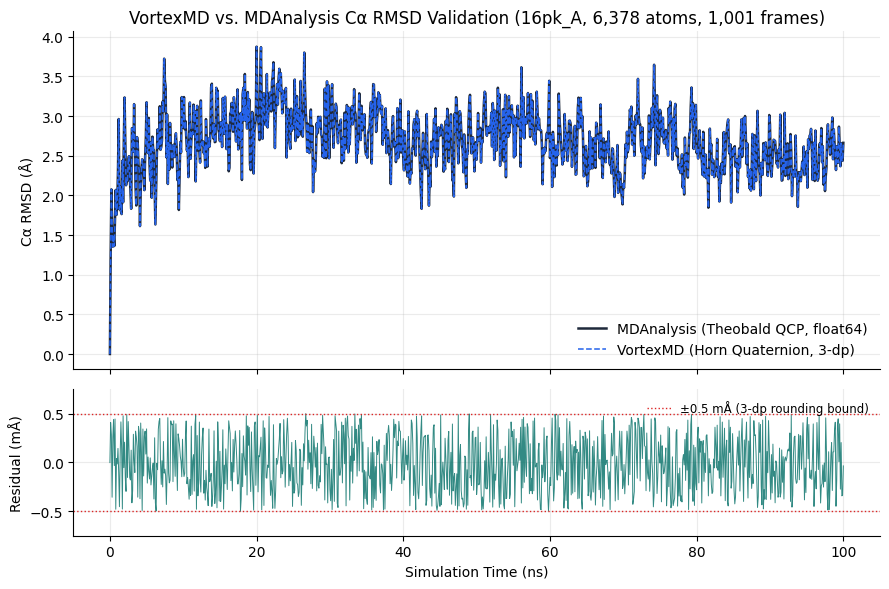

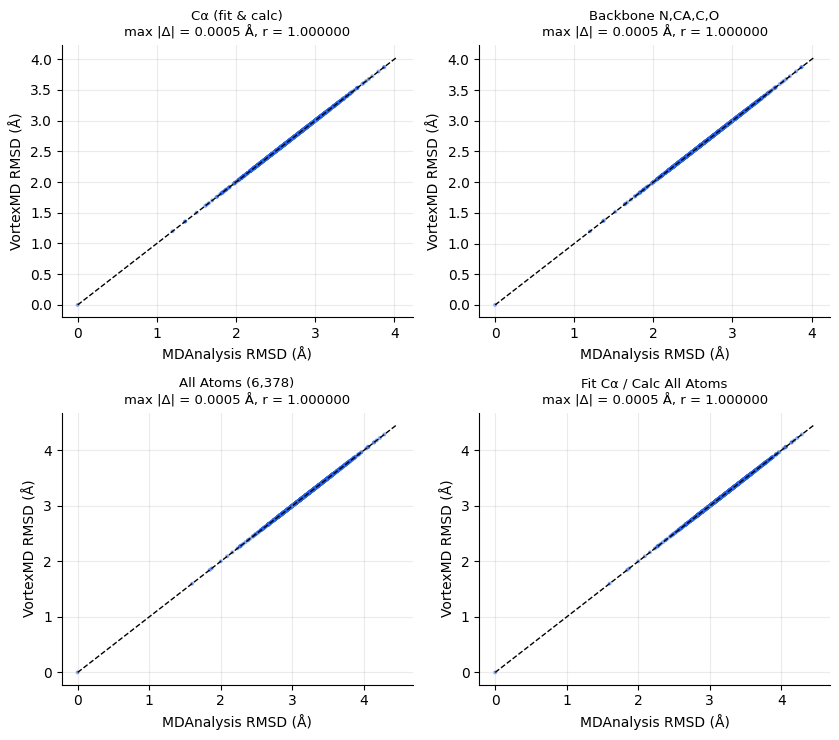

2026-11-24 05:03:07 | INFO | === All Results Written to Drive ===


INFO:vortexmd_validation:=== All Results Written to Drive ===


2026-11-24 05:03:07 | INFO |   rmsd_frame_by_frame_16pk_A.csv          113,498 bytes


INFO:vortexmd_validation:  rmsd_frame_by_frame_16pk_A.csv          113,498 bytes


2026-11-24 05:03:07 | INFO |   rmsd_frame_by_frame_demo.csv              2,707 bytes


INFO:vortexmd_validation:  rmsd_frame_by_frame_demo.csv              2,707 bytes


... (11 outputs left out)

INFO:vortexmd_validation:  rmsd_parity_scatter.png                 286,998 bytes


2026-11-24 05:03:08 | INFO |   validation_run.log                        3,170 bytes


INFO:vortexmd_validation:  validation_run.log                        3,170 bytes



Done! All logs, CSV/JSON tables, and figures saved to: /content/drive/MyDrive/vortexMD_rmsd_check/results


In [6]:
# 6. Generate 300 DPI publication-ready validation figures (saved to Drive + shown inline)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

# Figure 1: C-alpha RMSD overlay & frame-by-frame residuals
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
t_ns = frame_df['time_ns'].values

ax1.plot(t_ns, frame_df['mda_ca_A'], color='#1e293b', lw=1.8, label='MDAnalysis (Theobald QCP, float64)')
ax1.plot(t_ns, frame_df['vmd_ca_A'], color='#2563eb', lw=1.1, ls='--', label='VortexMD (Horn Quaternion, 3-dp)')
ax1.set_ylabel('Cα RMSD (Å)')
ax1.set_title('VortexMD vs. MDAnalysis Cα RMSD Validation (16pk_A, 6,378 atoms, 1,001 frames)')
ax1.legend(frameon=False, loc='lower right')
ax1.grid(alpha=0.25)

res_mA = frame_df['delta_ca_A'].values * 1000.0  # milli-Angstrom
ax2.plot(t_ns, res_mA, color='#0f766e', lw=0.7, alpha=0.85)
ax2.axhline(0.5, color='#dc2626', ls=':', lw=1.0, label='±0.5 mÅ (3-dp rounding bound)')
ax2.axhline(-0.5, color='#dc2626', ls=':', lw=1.0)
ax2.set_ylabel('Residual (mÅ)')
ax2.set_xlabel('Simulation Time (ns)')
ax2.set_ylim(-0.75, 0.75)
ax2.legend(frameon=False, loc='upper right', fontsize=8.5)
ax2.grid(alpha=0.25)

plt.tight_layout()
fig.savefig(RESULTS_DIR / 'rmsd_overlay_and_residuals.png', dpi=300, bbox_inches='tight')
fig.savefig(RESULTS_DIR / 'rmsd_overlay_and_residuals.pdf', bbox_inches='tight')
plt.show()

# Figure 2: 4-panel parity scatter across all selection modes
fig2, axes = plt.subplots(2, 2, figsize=(8.5, 7.5))
pairs = [
    ('Cα (fit & calc)', frame_df['mda_ca_A'], frame_df['vmd_ca_A']),
    ('Backbone N,CA,C,O', frame_df['mda_bb_A'], frame_df['vmd_bb_A']),
    ('All Atoms (6,378)', frame_df['mda_all_A'], frame_df['vmd_all_A']),
    ('Fit Cα / Calc All Atoms', frame_df['mda_fitca_calcall_A'], frame_df['vmd_fitca_calcall_A']),
]
for ax, (title, mx, vy) in zip(axes.flat, pairs):
    lo, hi = min(mx.min(), vy.min()), max(mx.max(), vy.max()) * 1.04
    ax.scatter(mx, vy, s=8, alpha=0.55, color='#2563eb', edgecolors='none')
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1.0, label='y = x')
    max_d = np.max(np.abs(vy - mx))
    r_val = np.corrcoef(mx, vy)[0, 1]
    ax.set_title(f'{title}\nmax |Δ| = {max_d:.4f} Å, r = {r_val:.6f}', fontsize=9.5)
    ax.set_xlabel('MDAnalysis RMSD (Å)')
    ax.set_ylabel('VortexMD RMSD (Å)')
    ax.grid(alpha=0.25)

plt.tight_layout()
fig2.savefig(RESULTS_DIR / 'rmsd_parity_scatter.png', dpi=300, bbox_inches='tight')
fig2.savefig(RESULTS_DIR / 'rmsd_parity_scatter.pdf', bbox_inches='tight')
plt.show()

# Final manifest of generated files in Drive
logger.info("=== All Results Written to Drive ===")
for p in sorted(RESULTS_DIR.iterdir()):
    logger.info(f"  {p.name:36s} {p.stat().st_size:>10,d} bytes")
print(f"\nDone! All logs, CSV/JSON tables, and figures saved to: {RESULTS_DIR}")
